# Chạy GMM trên tập feature A (RFM)

Thí nghiệm **Gaussian Mixture Model (GMM)** phân cụm khách hàng theo RFM trên bộ dữ liệu **Online Retail** (`data/raw/Online Retail.xlsx`).

Quy trình: **làm sạch dữ liệu raw → tính RFM → chuẩn hóa → chọn số thành phần và loại hiệp phương sai → train GMM → mô tả cụm → lưu kết quả**.


## Params

In [1]:
RANDOM_STATE = 42
N_INIT = 10
MAX_ITER = 300
TOL = 1e-3              
REG_COVAR = 1e-6
INIT_PARAMS = "kmeans"
K_RANGE = range(2, 11)
COV_TYPES = ["full", "tied", "diag", "spherical"]
MIN_CLUSTER_FRAC = 0.01   

REFERENCE_DATE = "2011-12-10"   
FEATURE_A = ["Recency", "Frequency", "Monetary"]

## import thư viện

In [2]:
import json, os, warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "Online Retail.xlsx").exists())
RAW_XLSX = ROOT / "data" / "raw" / "Online Retail.xlsx"
os.makedirs("figures", exist_ok=True); os.makedirs("data", exist_ok=True)
print("Project:", ROOT)

ModuleNotFoundError: No module named 'joblib'

## Đọc dữ liệu raw

In [ ]:
raw = pd.read_excel(RAW_XLSX, sheet_name="Online Retail")   
print("shape:", raw.shape)
display(raw.head())
display(raw[["Quantity", "UnitPrice"]].describe(percentiles=[.01, .25, .5, .75, .99]).T)
display(raw.isna().sum().to_frame("Số thiếu"))

shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.5500,"17,850.0000",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.7500,"17,850.0000",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom


,count,mean,std,min,1%,25%,50%,75%,99%,max
Quantity,"541,909.0000",9.5522,218.0812,"-80,995.0000",-2.0000,1.0000,3.0000,10.0000,100.0000,"80,995.0000"
UnitPrice,"541,909.0000",4.6111,96.7599,"-11,062.0600",0.1900,1.2500,2.0800,4.1300,18.0000,"38,970.0000"


,Số thiếu
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


## Làm sạch dữ liệu

Mỗi dòng raw là một mặt hàng trên một hóa đơn, còn RFM tính theo khách hàng, nên chỉ giữ **giao dịch mua hợp lệ của khách có mã**:

1. **Chuẩn hóa văn bản** (bỏ khoảng trắng, viết hoa `InvoiceNo`, `StockCode`, `Description`; `EIRE` → `Ireland`) trước khi tìm dòng trùng.
2. **Bỏ dòng trùng hoàn toàn**: một giao dịch ghi hai lần sẽ làm tăng ảo Frequency và Monetary.
3. **Bỏ hóa đơn hủy** (`InvoiceNo` bắt đầu bằng `C`), giữ `Quantity > 0` và `UnitPrice > 0`: để Monetary là tiền khách đã mua, không bị tiền âm triệt tiêu; hàng giá 0 và bút toán kho không phải giao dịch mua.
4. **Bỏ mã hàng đặc biệt** (`POST`, `M`, `BANK CHARGES`, `AMAZONFEE`...): là phí/chiết khấu, không phải sản phẩm.
5. **Bỏ ngoại lai cực đoan**: ngoài [Q1 − 3×IQR, Q3 + 3×IQR] trên thang `log1p` của `Quantity` và `UnitPrice`. Dùng thang log vì dữ liệu lệch phải mạnh, dùng hệ số 3 (thay vì 1,5) để không xóa nhầm khách mua sỉ thật, vốn là nhóm khách giá trị cao cần tìm.
6. **Bỏ dòng thiếu `CustomerID`**: không có mã thì không biết dòng thuộc khách nào, và không điền mã được vì sẽ gán nhầm giao dịch cho khách khác.

In [ ]:
SPECIAL_CODES = {"POST", "DOT", "M", "C2", "C3", "D", "S", "B", "BANK CHARGES", "ADJUST", "ADJUST2",
                 "AMAZONFEE", "CRUK", "TEST001", "TEST002"}

def outlier_mask(frame, cols=("Quantity", "UnitPrice"), k=3.0):
    mask = pd.Series(False, index=frame.index)
    for col in cols:
        x = np.log1p(frame[col]); q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
        mask |= (x < q1 - k * iqr) | (x > q3 + k * iqr)
    return mask

log = [("Dữ liệu raw", len(raw))]
d = raw.copy()


d["Description"] = d["Description"].fillna("Unknown Product").astype(str).str.strip().str.upper()
d["InvoiceNo"] = d["InvoiceNo"].astype(str).str.strip().str.upper()
d["StockCode"] = d["StockCode"].astype(str).str.strip().str.upper()
d["Country"] = d["Country"].astype(str).str.strip().replace({"EIRE": "Ireland"})


d = d.drop_duplicates();                                          log.append(("2. Bỏ dòng trùng hoàn toàn", len(d)))

d = d[~d["InvoiceNo"].str.startswith("C")];                       log.append(("3a. Bỏ hóa đơn hủy (C)", len(d)))
d = d[(d["Quantity"] > 0) & (d["UnitPrice"] > 0)];                log.append(("3b. Giữ Quantity > 0 và UnitPrice > 0", len(d)))

d = d[~d["StockCode"].isin(SPECIAL_CODES)];                       log.append(("4. Bỏ mã hàng đặc biệt", len(d)))

d = d[~outlier_mask(d)];                                          log.append(("5. Bỏ ngoại lai cực đoan (IQR x 3 trên log1p)", len(d)))

d = d[d["CustomerID"].notna()].copy();                            log.append(("6. Bỏ dòng thiếu CustomerID", len(d)))
d["CustomerID"] = d["CustomerID"].astype(int).astype(str)
d["Revenue"] = d["Quantity"] * d["UnitPrice"]

clean_log = pd.DataFrame(log, columns=["Bước", "Số dòng còn lại"])
clean_log["Số dòng bị loại"] = (-clean_log["Số dòng còn lại"].diff()).fillna(0).astype(int)
clean_log["% còn lại so với raw"] = (clean_log["Số dòng còn lại"] / len(raw) * 100).round(2)
display(clean_log)
print("Sau làm sạch:", d.shape, "| khách:", d["CustomerID"].nunique(), "| hóa đơn:", d["InvoiceNo"].nunique(), "| từ", d["InvoiceDate"].min(), "đến", d["InvoiceDate"].max())

,Bước,Số dòng còn lại,Số dòng bị loại,% còn lại so với raw
0,Dữ liệu raw,541909,0,100.0000
1,2. Bỏ dòng trùng hoàn toàn,536641,5268,99.0300
2,3a. Bỏ hóa đơn hủy (C),527390,9251,97.3200
3,3b. Giữ Quantity > 0 và UnitPrice > 0,524878,2512,96.8600
4,4. Bỏ mã hàng đặc biệt,522571,2307,96.4300
5,5. Bỏ ngoại lai cực đoan (IQR x 3 trên log1p),522388,183,96.4000
6,6. Bỏ dòng thiếu CustomerID,390987,131401,72.1500


Sau làm sạch: (390987, 9) | khách: 4327 | hóa đơn: 18373 | từ 2010-12-01 08:26:00 đến 2011-12-09 12:50:00


**Nhận xét:**
* Từ **541.909 dòng raw còn 390.987 dòng (72,2%)**, gồm **4.327 khách** và 18.373 hóa đơn. Bước loại nhiều nhất là bỏ dòng thiếu `CustomerID` (131.401 dòng sau các bước trước, khoảng 24% raw), tiếp theo là hóa đơn hủy (9.251), dòng trùng (5.268), `Quantity`/`UnitPrice` không dương (2.512), mã hàng đặc biệt (2.307) và ngoại lai cực đoan (183).
* Các dòng thiếu `CustomerID` buộc phải bỏ vì RFM tính theo khách; điền mã sẽ gán giao dịch cho khách khác và làm sai Frequency, Monetary.

## Tính RFM

* **Recency**: số ngày từ ngày mua gần nhất đến ngày tham chiếu (`REFERENCE_DATE`).
* **Frequency**: số hóa đơn khác nhau của khách.
* **Monetary**: tổng `Quantity × UnitPrice` (GBP) trên các dòng mua.

In [ ]:
ref = pd.Timestamp(REFERENCE_DATE)
g = d.groupby("CustomerID")
df = pd.DataFrame({
    "Recency": (ref - g["InvoiceDate"].max().dt.normalize()).dt.days,
    "Frequency": g["InvoiceNo"].nunique(),
    "Monetary": g["Revenue"].sum(),
}).reset_index()
assert df["CustomerID"].is_unique and (df["Recency"] >= 0).all() and (df["Frequency"] > 0).all() and (df["Monetary"] > 0).all()
df.to_csv("data/customer_features.csv", index=False)
print("RFM:", df.shape)
display(df.head())
display(df[FEATURE_A].describe(percentiles=[.25, .5, .75, .99]).T)
display(df[FEATURE_A].skew().to_frame("Skew"))

RFM: (4327, 4)


,CustomerID,Recency,Frequency,Monetary
0,12347,3,7,"4,310.0000"
1,12348,76,4,"1,437.2400"
2,12349,19,1,"1,457.5500"
3,12350,311,1,294.4000
4,12352,37,7,"1,385.7400"


,count,mean,std,min,25%,50%,75%,99%,max
Recency,"4,327.0000",93.0381,99.9769,1.0000,18.0000,51.0000,143.0000,369.0000,374.0000
Frequency,"4,327.0000",4.2461,7.6392,1.0000,1.0000,2.0000,5.0000,30.0000,206.0000
Monetary,"4,327.0000","1,944.9476","8,441.8896",2.9000,301.5200,657.9000,"1,624.0950","17,279.0574","278,748.0200"


,Skew
Recency,1.2464
Frequency,11.9482
Monetary,21.0356


## kiểm tra lại missing RFM

In [ ]:
X = df[FEATURE_A].copy()
print("Missing RFM:", int(X.isna().sum().sum()), "| Recency<0:", int((X.Recency < 0).sum()), "| Frequency<=0:", int((X.Frequency <= 0).sum()), "| Monetary<=0:", int((X.Monetary <= 0).sum()))

Missing RFM: 0 | Recency<0: 0 | Frequency<=0: 0 | Monetary<=0: 0


**Nhận xét:**
* RFM lệch phải rất mạnh: skew của Recency ≈ 1,25, Frequency ≈ 11,9, Monetary ≈ 21,0. Monetary trung vị chỉ khoảng 658 nhưng lớn nhất khoảng 278.748; Frequency trung vị 2 nhưng lớn nhất 206. Vì vậy cần chuẩn hóa, và `log1p` là lựa chọn đáng thử (cấu hình B).
* Frequency nhận giá trị nguyên, và khoảng 35% khách chỉ mua đúng 1 lần, điều này ảnh hưởng đến cách đọc BIC ở bên dưới.

## Scaling lại dữ liệu

* `Monetary` lớn hơn `Recency`, `Frequency` hàng trăm đến hàng nghìn lần nên nếu không chuẩn hóa thì `Monetary` quyết định gần như toàn bộ hình dạng các thành phần Gauss.
* **Cấu hình A:** `StandardScaler` trên RFM thô. **Cấu hình B:** thêm `log1p` trước khi chuẩn hóa, vì RFM lệch phải rất mạnh.

In [ ]:
CONFIGS = {
    "A. RFM thô + StandardScaler": False,
    "B. log1p + StandardScaler": True,
}

def make_scaled(frame, use_log):
    Xr = frame[FEATURE_A].astype(float)
    Xt = np.log1p(Xr) if use_log else Xr
    return Xr, StandardScaler().fit_transform(Xt)

def sweep(Xs):
    rows = []
    for cov in COV_TYPES:
        for k in K_RANGE:
            gm = GaussianMixture(n_components=k, covariance_type=cov, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL,
                                 reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit(Xs)
            lab = gm.predict(Xs); sizes = np.bincount(lab, minlength=k)
            ok = len(np.unique(lab)) > 1
            rows.append({"covariance_type": cov, "k": k, "BIC": gm.bic(Xs), "AIC": gm.aic(Xs),
                         "Silhouette": silhouette_score(Xs, lab) if ok else np.nan,
                         "DBI": davies_bouldin_score(Xs, lab) if ok else np.nan,
                         "CHI": calinski_harabasz_score(Xs, lab) if ok else np.nan,
                         "min_cluster": int(sizes.min()), "converged": bool(gm.converged_)})
    return pd.DataFrame(rows)

def select(res, n):
    
    ok = res[res["converged"] & (res["min_cluster"] >= MIN_CLUSTER_FRAC * n)]
    return ok.loc[ok["BIC"].idxmin()]

## Chọn số thành phần k và loại hiệp phương sai

Với GMM, chỉ số chính là **BIC** (càng thấp càng tốt, có phạt độ phức tạp). Silhouette, DBI, CHI tính trên `X_scaled` chỉ để tham khảo vì GMM là mô hình xác suất (các cụm có thể chồng lấn). Mỗi cấu hình quét `k = 2..10` × 4 loại `covariance_type`.

In [ ]:
results, picks = {}, {}
for name, use_log in CONFIGS.items():
    Xr, Xs = make_scaled(df, use_log)
    results[name] = sweep(Xs); picks[name] = select(results[name], len(df))
    p = picks[name]
    print(f"{name}: chọn {p['covariance_type']}, k={int(p['k'])}, BIC={p['BIC']:,.1f}, Silhouette={p['Silhouette']:.3f}, cụm nhỏ nhất={int(p['min_cluster'])}")

main = list(CONFIGS)[0]
res_main = results[main]
display(res_main.loc[res_main.groupby("covariance_type")["BIC"].idxmin()].round(4).reset_index(drop=True))
display(res_main[res_main["covariance_type"] == picks[main]["covariance_type"]].drop(columns=["covariance_type"]).round(4))

A. RFM thô + StandardScaler: chọn diag, k=6, BIC=-11,514.1, Silhouette=0.023, cụm nhỏ nhất=70


B. log1p + StandardScaler: chọn full, k=10, BIC=-9,362.1, Silhouette=0.109, cụm nhỏ nhất=67


,covariance_type,k,BIC,AIC,Silhouette,DBI,CHI,min_cluster,converged
0,diag,10,"-18,657.0954","-19,096.8068",-0.0919,1.9543,581.0732,2,True
1,full,10,"-18,543.8805","-19,174.7708",-0.0999,1.8090,896.4833,2,True
2,spherical,10,"7,960.7264","7,648.4676",0.3860,0.8146,"3,159.1193",3,True
3,tied,10,"16,169.1935","15,882.4252",0.5156,0.6767,"4,052.5541",2,True


,k,BIC,AIC,Silhouette,DBI,CHI,min_cluster,converged
18,2,"11,405.5391","11,322.6949",0.3422,1.3000,822.0673,982,True
19,3,"4,735.7820","4,608.3294",0.1638,1.2492,937.6857,212,True
20,4,"-9,344.3787","-9,516.4397",0.0711,1.7505,649.9406,199,True
21,5,"-9,727.7674","-9,944.4368",0.0559,1.6350,884.8299,47,True
22,6,"-11,514.0754","-11,775.3532",0.0226,1.8769,645.7863,70,True
23,7,"-11,661.5016","-11,967.3879",0.0073,2.2465,511.9464,38,True
24,8,"-12,301.8494","-12,652.3441",0.0018,2.9978,607.6838,26,True
25,9,"-18,541.0118","-18,936.1148",-0.0910,2.3546,461.7300,26,True
26,10,"-18,657.0954","-19,096.8068",-0.0919,1.9543,581.0732,2,True


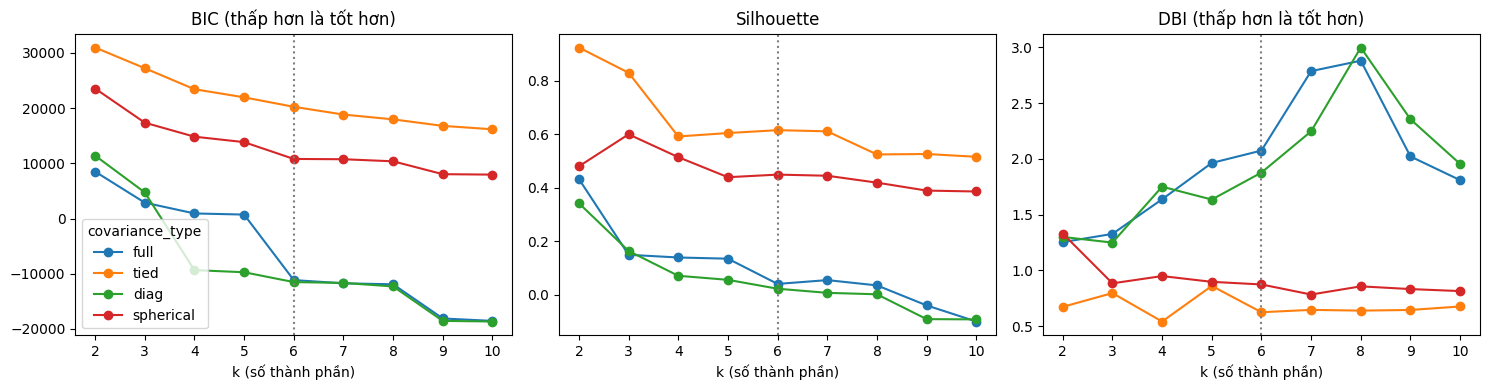

Mô hình được chọn (cấu hình A): {'covariance_type': 'diag', 'k': np.int64(6), 'BIC': np.float64(-11514.075371487208), 'Silhouette': np.float64(0.02263807438968161)}
Silhouette cao nhất: {'covariance_type': 'tied', 'k': np.int64(2), 'Silhouette': np.float64(0.9238920762241843), 'min_cluster': np.int64(13)}


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BIC", "Silhouette", "DBI"]):
    for cov in COV_TYPES:
        s = res_main[res_main["covariance_type"] == cov]
        ax.plot(s["k"], s[col], marker="o", label=cov)
    ax.axvline(int(picks[main]["k"]), color="gray", ls=":")
    ax.set_xlabel("k (số thành phần)"); ax.set_title(col + (" (thấp hơn là tốt hơn)" if col in ("BIC", "DBI") else ""))
axes[0].legend(title="covariance_type")
plt.tight_layout(); fig.savefig("figures/gmm_metrics.png", dpi=300, bbox_inches="tight"); plt.show()
print("Mô hình được chọn (cấu hình A):", dict(picks[main][["covariance_type", "k", "BIC", "Silhouette"]]))
print("Silhouette cao nhất:", dict(res_main.loc[res_main["Silhouette"].idxmax(), ["covariance_type", "k", "Silhouette", "min_cluster"]]))

**Nhận xét (cấu hình A: RFM thô + StandardScaler):**
* BIC giảm dần khi tăng k và thấp nhất ở k = 10 (`diag`), nhưng mô hình đó có cụm chỉ **2 khách** (mô hình đang "bắt" riêng vài ngoại lai) nên bị loại theo quy tắc mỗi cụm ≥ 1% số khách (~43 khách). Mô hình được chọn: **`diag`, k = 6**, BIC ≈ -11.514, Silhouette ≈ 0,023, DBI ≈ 1,88, cụm nhỏ nhất 70 khách.
* Silhouette cao nhất (≈ 0,92) rơi vào `tied`, k = 2 nhưng cụm nhỏ chỉ 13 khách: đó chỉ là cách tách một nhóm VIP rất ít người khỏi số đông, không cho thấy cấu trúc phân khúc.
* **Cẩn thận khi đọc BIC:** từ k = 4 BIC tụt rất mạnh (≈ 4.736 ở k = 3 xuống ≈ -9.344 ở k = 4) vì một thành phần có phương sai của Frequency chạm sàn `reg_covar` (1e-6): khoảng 35% khách chỉ mua đúng 1 lần nên mật độ của thành phần đó bị đẩy lên rất cao. Vì vậy BIC của `diag`/`full` ở k ≥ 4 bị thổi phồng, chỉ nên dùng để so sánh tương đối. Silhouette gần 0 cho thấy các cụm chồng lấn mạnh.

## Train model với tham số đã chọn

In [ ]:
def fit_final(frame, use_log, row):
    Xr, Xs = make_scaled(frame, use_log)
    gm = GaussianMixture(n_components=int(row["k"]), covariance_type=row["covariance_type"], n_init=N_INIT, max_iter=MAX_ITER,
                         tol=TOL, reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit(Xs)
    lab = gm.predict(Xs); proba = gm.predict_proba(Xs)
    out = frame[["CustomerID"] + FEATURE_A].copy(); out["cluster"] = lab; out["max_proba"] = proba.max(axis=1)
    return gm, Xs, lab, out

model, X_scaled, labels, result = fit_final(df, CONFIGS[main], picks[main])
print("Số lượng theo cụm:"); print(result["cluster"].value_counts().sort_index())
print("Hội tụ:", model.converged_, "| số vòng EM:", model.n_iter_, "| BIC:", round(model.bic(X_scaled), 1))
print("Silhouette:", round(silhouette_score(X_scaled, labels), 4), "| DBI:", round(davies_bouldin_score(X_scaled, labels), 4), "| CHI:", round(calinski_harabasz_score(X_scaled, labels), 2))
display(result.head())

Số lượng theo cụm:
cluster
0    1271
1    1442
2      70
3    1037
4     383
5     124
Name: count, dtype: int64
Hội tụ: True | số vòng EM: 29 | BIC: -11514.1
Silhouette: 0.0226 | DBI: 1.8769 | CHI: 645.79


,CustomerID,Recency,Frequency,Monetary,cluster,max_proba
0,12347,3,7,"4,310.0000",4,0.9266
1,12348,76,4,"1,437.2400",3,0.9091
2,12349,19,1,"1,457.5500",3,0.8528
3,12350,311,1,294.4000,1,1.0000
4,12352,37,7,"1,385.7400",3,0.9960


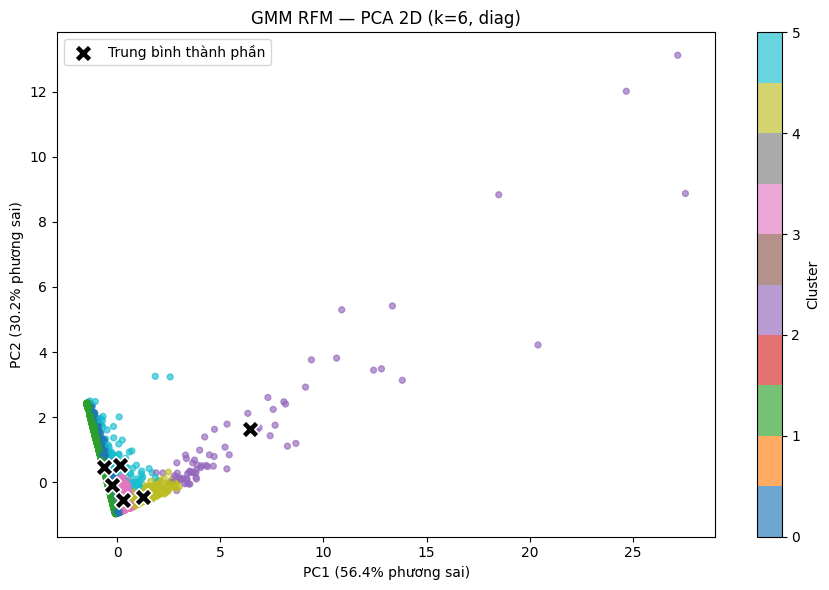

In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
centers_2d = pca.transform(model.means_)

fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(coords[:, 0], coords[:, 1], c=labels, cmap="tab10", s=18, alpha=0.65, rasterized=True)
ax.scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker="X", s=160, edgecolors="white", linewidths=1.2, label="Trung bình thành phần")
ax.set_title(f"GMM RFM — PCA 2D (k={model.n_components}, {model.covariance_type})")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} phương sai)"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} phương sai)")
ax.legend(loc="best"); fig.colorbar(scatter, ax=ax, label="Cluster", ticks=sorted(np.unique(labels)))
fig.tight_layout(); fig.savefig("figures/gmm_clusters_pca.png", dpi=300, bbox_inches="tight"); plt.show()

In [ ]:
cluster_count = result["cluster"].value_counts().sort_index()
cluster_summary = pd.DataFrame({"Số khách hàng": cluster_count, "Tỷ lệ (%)": (cluster_count / len(result) * 100).round(2)})
profile = result.groupby("cluster")[FEATURE_A].median()
profile["max_proba (TB)"] = result.groupby("cluster")["max_proba"].mean()
display(cluster_summary.join(profile))
print("Khách có xác suất cụm cao nhất < 0.8 (thuộc cụm không rõ ràng):", int((result["max_proba"] < 0.8).sum()), f"({(result['max_proba'] < 0.8).mean():.1%})")

,Số khách hàng,Tỷ lệ (%),Recency,Frequency,Monetary,max_proba (TB)
cluster,,,,,,
0,1271,29.3700,67.0000,2.0000,592.9700,0.9121
1,1442,33.3300,134.0000,1.0000,238.2300,0.9947
2,70,1.6200,4.0000,32.5000,"21,252.8450",0.9710
3,1037,23.9700,24.0000,5.0000,"1,625.9700",0.8869
4,383,8.8500,10.0000,12.0000,"4,545.8900",0.9079
5,124,2.8700,137.5000,5.0000,"2,970.9900",0.9010


Khách có xác suất cụm cao nhất < 0.8 (thuộc cụm không rõ ràng): 522 (12.1%)


## số lượng khách hàng theo từng cụm

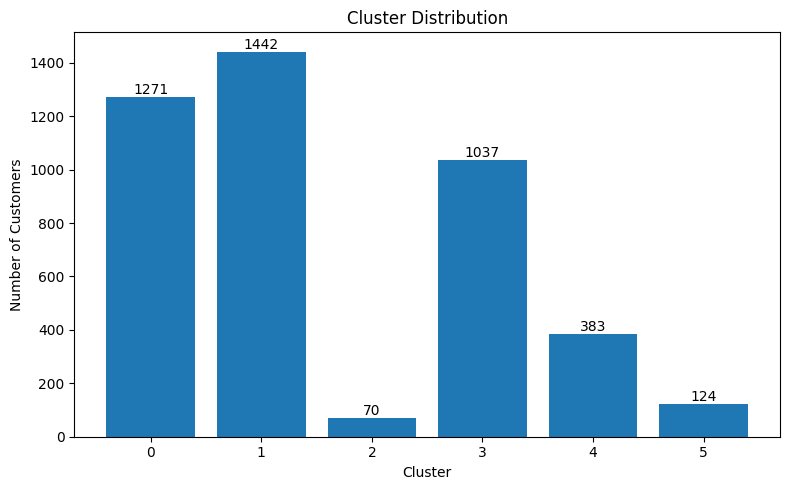

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(cluster_count.index, cluster_count.values)
ax.set_title("Cluster Distribution"); ax.set_xlabel("Cluster"); ax.set_ylabel("Number of Customers"); ax.set_xticks(cluster_count.index)
for i, count in zip(cluster_count.index, cluster_count): ax.text(i, count, str(count), ha="center", va="bottom")
plt.tight_layout(); fig.savefig("figures/gmm_cluster_distribution.png", dpi=300); plt.show()

## RFM theo từng cụm

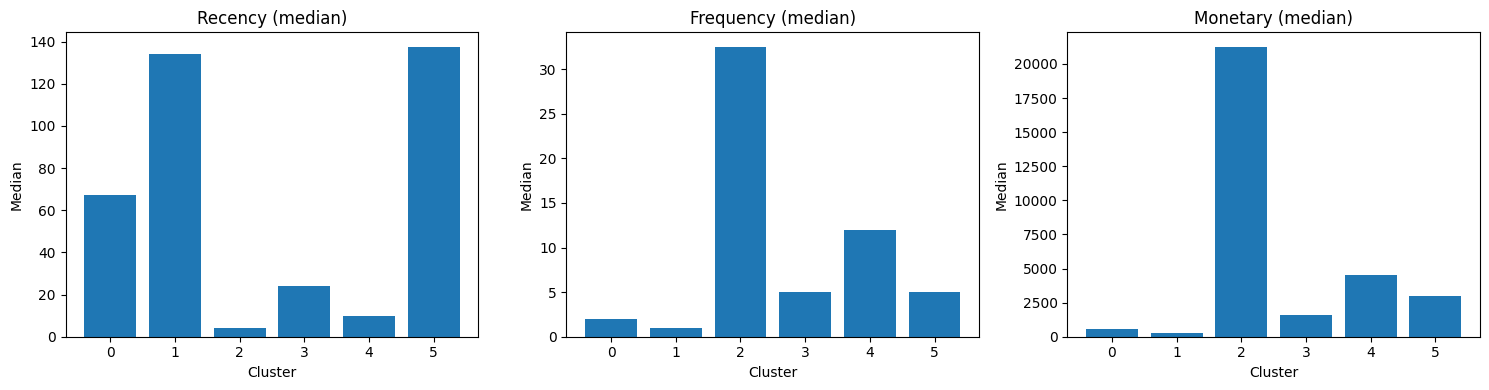

In [ ]:
rfm = result.groupby("cluster")[FEATURE_A].median()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, FEATURE_A):
    ax.bar(rfm.index, rfm[feature]); ax.set_title(feature + " (median)"); ax.set_xlabel("Cluster"); ax.set_ylabel("Median"); ax.set_xticks(rfm.index)
plt.tight_layout(); fig.savefig("figures/gmm_rfm_comparison.png", dpi=300); plt.show()

**Nhận xét (cấu hình A, `diag`, k = 6):** mô tả dựa trên trung vị RFM của từng cụm; tên nhóm chỉ là cách gọi gợi ý, chưa phải kết luận của mô hình.

* Cụm 1 (1.442 khách, 33,3%): Recency 134 ngày, Frequency 1, Monetary ≈ 238 → **mua một lần, lâu chưa quay lại**.
* Cụm 0 (1.271 khách, 29,4%): Recency 67, Frequency 2, Monetary ≈ 593 → **ít mua, chi tiêu thấp, hoạt động ở mức trung bình**.
* Cụm 3 (1.037 khách, 24,0%): Recency 24, Frequency 5, Monetary ≈ 1.626 → **khách khá thường xuyên và còn hoạt động**.
* Cụm 4 (383 khách, 8,9%): Recency 10, Frequency 12, Monetary ≈ 4.546 → **khách trung thành, chi tiêu cao**.
* Cụm 5 (124 khách, 2,9%): Recency 137,5, Frequency 5, Monetary ≈ 2.971 → **từng chi tiêu khá nhưng lâu chưa mua (nguy cơ rời bỏ)**.
* Cụm 2 (70 khách, 1,6%): Recency 4, Frequency 32,5, Monetary ≈ 21.253 → **nhóm VIP**.

GMM chia được cả các phân khúc trung gian, không chỉ tách VIP khỏi số đông. Đổi lại ranh giới giữa các cụm **mờ**: 522 khách (12,1%) có xác suất cụm cao nhất dưới 0,8, khớp với Silhouette thấp.

## So sánh 2 cấu hình

Cấu hình A là RFM thô, cấu hình B thêm `log1p`. Mỗi cấu hình dùng cùng quy tắc chọn: BIC thấp nhất, hội tụ, mỗi cụm ≥ 1% số khách.

In [ ]:
rows, fitted, profiles = [], {}, {}
for name, use_log in CONFIGS.items():
    gm, Xs, lab, out = fit_final(df, use_log, picks[name]); fitted[name] = (gm, lab, out)
    sizes = sorted(np.bincount(lab).tolist(), reverse=True)
    best_sil = results[name].loc[results[name]["Silhouette"].idxmax()]
    rows.append({"Cấu hình": name, "covariance": gm.covariance_type, "k": gm.n_components, "BIC": gm.bic(Xs),
                 "Silhouette": silhouette_score(Xs, lab), "DBI": davies_bouldin_score(Xs, lab), "CHI": calinski_harabasz_score(Xs, lab),
                 "Kích thước cụm": sizes, "Silhouette cao nhất (cov, k)": f"{best_sil['Silhouette']:.3f} ({best_sil['covariance_type']}, k={int(best_sil['k'])}, cụm nhỏ nhất {int(best_sil['min_cluster'])})"})
    p = out.groupby("cluster")[FEATURE_A].median(); p.insert(0, "Số khách", out["cluster"].value_counts().sort_index()); p.insert(1, "Tỷ lệ (%)", (p["Số khách"] / len(out) * 100).round(2))
    profiles[name] = p
compare = pd.DataFrame(rows).set_index("Cấu hình")
display(compare)
for name, p in profiles.items():
    print("\n" + name); display(p)

,covariance,k,BIC,Silhouette,DBI,CHI,Kích thước cụm,"Silhouette cao nhất (cov, k)"
Cấu hình,,,,,,,,
A. RFM thô + StandardScaler,diag,6,"-11,514.0754",0.0226,1.8769,645.7863,"[1442, 1271, 1037, 383, 124, 70]","0.924 (tied, k=2, cụm nhỏ nhất 13)"
B. log1p + StandardScaler,full,10,"-9,362.0931",0.1091,3.1674,"1,140.9374","[877, 829, 627, 501, 405, 392, 238, 219, 172, 67]","0.431 (spherical, k=2, cụm nhỏ nhất 1680)"



A. RFM thô + StandardScaler


,Số khách,Tỷ lệ (%),Recency,Frequency,Monetary
cluster,,,,,
0,1271,29.3700,67.0000,2.0000,592.9700
1,1442,33.3300,134.0000,1.0000,238.2300
2,70,1.6200,4.0000,32.5000,"21,252.8450"
3,1037,23.9700,24.0000,5.0000,"1,625.9700"
4,383,8.8500,10.0000,12.0000,"4,545.8900"
5,124,2.8700,137.5000,5.0000,"2,970.9900"



B. log1p + StandardScaler


,Số khách,Tỷ lệ (%),Recency,Frequency,Monetary
cluster,,,,,
0,219,5.0600,5.0000,15.0000,"4,812.4200"
1,877,20.2700,60.0000,1.0000,284.5500
2,501,11.5800,47.0000,3.0000,817.8600
3,392,9.0600,32.0000,4.0000,"1,178.2600"
4,829,19.1600,64.0000,2.0000,537.4800
5,238,5.5000,28.0000,5.0000,"1,553.5500"
6,172,3.9800,23.0000,6.0000,"1,921.0800"
7,67,1.5500,5.0000,33.0000,"25,301.5400"
8,405,9.3600,19.0000,8.0000,"2,709.7000"


**Nhận xét so sánh 2 cấu hình:**
* Cả hai cấu hình đều cho cùng bức tranh: một nhóm **VIP rất nhỏ** (67–70 khách, khoảng 1,5%, Monetary trung vị 21.000–25.000, mua gần như mới đây), một nhóm lớn **mua một lần, lâu chưa quay lại** và các phân khúc trung gian. Silhouette chỉ ≈ 0,02 (A) và ≈ 0,11 (B), nên cấu trúc cụm yếu và chồng lấn; nên xem GMM ở đây như phân khúc "mềm".
* **Thêm `log1p` (B)** cho Silhouette cao hơn và các cụm cân đối hơn (67–877 khách) nhưng số cụm được chọn đúng bằng biên trên của khoảng quét (k = 10), nên số cụm thật có thể nhiều hơn mức đã quét. Cần quyết định có dùng `log1p` ở bước chuẩn hóa hay không.
* BIC không so sánh được giữa A và B vì dữ liệu hai cấu hình khác thang đo.

# lưu tham số mô hình

In [ ]:

print("BIC:", model.bic(X_scaled)); print("AIC:", model.aic(X_scaled))
print("Silhouette:", silhouette_score(X_scaled, labels)); print("DBI:", davies_bouldin_score(X_scaled, labels)); print("CHI:", calinski_harabasz_score(X_scaled, labels))


with open("gmm_params.json", "w") as f:
    json.dump(model.get_params(), f, indent=4)


pipe = Pipeline([("scaler", StandardScaler().fit(df[FEATURE_A])), ("gmm", model)])
joblib.dump(pipe, "gmm_model.pkl")

BIC: -11514.075371487208
AIC: -11775.353190836428


Silhouette: 0.02263807438968161
DBI: 1.8768840953568244
CHI: 645.7863415194165


['gmm_model.pkl']

In [ ]:

from openpyxl import Workbook
from openpyxl.styles import Font, Alignment

def describe_profile(p):
    med = df[FEATURE_A].median(); out = []
    for _, r in p.iterrows():
        out.append(", ".join(f"Recency {'xa (lâu chưa mua)' if r[c] > med[c] else 'gần'}" if c == "Recency" else f"{c} {'cao' if r[c] > med[c] else 'thấp'}" for c in FEATURE_A))
    return out

wb = Workbook(); ws = wb.active; ws.title = "GMM_RFM"
ws.append(["THÍ NGHIỆM GMM — FEATURE A (RFM)"]); ws["A1"].font = Font(bold=True, size=13)
ws.append(["Trạng thái", "Đã chạy mô hình; BIC/AIC/Silhouette/DBI/CHI tính trên X_scaled"]); ws.append([])
ws.append(["Thiết lập", "Giá trị", None, "Tham số khác", "Giá trị"])
settings = [("Feature", "Recency, Frequency, Monetary"), ("Dữ liệu train", "X_scaled (StandardScaler)"), ("Nguồn dữ liệu", "Online Retail.xlsx, đã làm sạch trong notebook"),
            ("covariance_type", model.covariance_type), ("k được chọn", model.n_components), ("random_state", RANDOM_STATE), ("n_init", N_INIT), ("init_params", INIT_PARAMS)]
others = [("max_iter", MAX_ITER), ("tol", TOL), ("reg_covar", REG_COVAR), ("Tổng khách hàng", len(df)), ("Số vòng EM", int(model.n_iter_)), ("Hội tụ", bool(model.converged_)), ("Quy tắc chọn", "BIC thấp nhất, mỗi cụm >= 1% số khách"), (None, None)]
for a, b in zip(settings, others): ws.append([a[0], a[1], None, b[0], b[1]])
ws.append([]); ws.append(["covariance_type", "k", "BIC", "AIC", "Silhouette", "DBI", "CHI", "Cụm nhỏ nhất", "Nhận xét"])
for _, r in res_main.iterrows():
    sel = (r["covariance_type"] == picks[main]["covariance_type"]) and (int(r["k"]) == int(picks[main]["k"]))
    ws.append([r["covariance_type"], int(r["k"]), round(r["BIC"], 2), round(r["AIC"], 2), None if pd.isna(r["Silhouette"]) else round(r["Silhouette"], 4),
               None if pd.isna(r["DBI"]) else round(r["DBI"], 4), None if pd.isna(r["CHI"]) else round(r["CHI"], 2), int(r["min_cluster"]), "được chọn" if sel else None])
ws.append([]); ws.append(["Cụm", "Mô tả (so với trung vị chung)", "Số khách", "Tỷ lệ (%)", "Recency (median)", "Frequency (median)", "Monetary (median)"])
p = profiles[main]
for (c, r), text in zip(p.iterrows(), describe_profile(p)): ws.append([int(c), text, int(r["Số khách"]), r["Tỷ lệ (%)"], r["Recency"], r["Frequency"], round(r["Monetary"], 2)])

ws2 = wb.create_sheet("So_sanh_cau_hinh")
ws2.append(["Cấu hình", "covariance", "k", "BIC", "Silhouette", "DBI", "CHI", "Kích thước cụm", "Silhouette cao nhất (cov, k)"])
for name, r in compare.iterrows():
    ws2.append([name, r["covariance"], int(r["k"]), round(r["BIC"], 1), round(r["Silhouette"], 4), round(r["DBI"], 4), round(r["CHI"], 1), str(r["Kích thước cụm"]), r["Silhouette cao nhất (cov, k)"]])

ws3 = wb.create_sheet("Lam_sach")
ws3.append(list(clean_log.columns))
for _, r in clean_log.iterrows(): ws3.append([r["Bước"], int(r["Số dòng còn lại"]), int(r["Số dòng bị loại"]), float(r["% còn lại so với raw"])])
for sheet in wb.worksheets:
    sheet.column_dimensions["A"].width = 46
    for col in "BCDEFGHIJ": sheet.column_dimensions[col].width = 20
    for row in sheet.iter_rows():
        for cell in row: cell.alignment = Alignment(wrap_text=True, vertical="top")
wb.save("Working_details_GMM_RFM.xlsx"); print("Đã lưu Working_details_GMM_RFM.xlsx")